# CLPM for clinical and cognition path effects

Results: Early cognitive improvement is a candidate contributor to later symptom improvement, but this analysis does not establish mediation through cognition.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

# project PATH
DATASET_NAME = "sz_meditation"
project_path_str="/scratch/repo_"+DATASET_NAME
project_path= Path(project_path_str)
sys.path.append(str(project_path))

# importing private libs and functions (imaging_arsenal version, need to import the parent dir as well)
private_lib_path = Path('/scratch/imaging_arsenal')
sys.path.append(str(private_lib_path))
sys.path.append(str(private_lib_path / 'utils_'))
print('private lib ready:',(private_lib_path / 'utils_private.py').exists())
from utils_.utils_private import report_cpu, report_unified_missingness
report_cpu()

# data path
data_path = project_path / 'data' 
basic_time_Tag = "20240724"
fig_path = project_path / 'fig' 

# data
all_DKT_path = data_path / (DATASET_NAME+'_R_'+basic_time_Tag+'.csv')
traj_data_path = data_path / "trajectory_class2_20240730.csv"

# read data
all_df = pd.read_csv(all_DKT_path, index_col= None)
tmp_df=all_df.copy()

private lib ready: False


/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


Total CPUs: 12
Total Memory: 29.38 GB
Available Memory: 22.98 GB


In [2]:
# report major software version
import statsmodels 
import nilearn
import sys
import sklearn
import semopy
import seaborn as sns
import networkx as nx
# setup random seed
rand_seed = 24
np.random.seed(rand_seed)

print('python version:', sys.version)
print('numpy version:', np.__version__)
print('statsmodels version:', statsmodels.__version__)
print('nilearn version:', nilearn.__version__)
print('sklearn version:', sklearn.__version__)
print('semopy version:', semopy.__version__)
print('networkX version:', nx.__version__)
print('seaborn version:', sns.__version__)
print('random seed:', rand_seed)

python version: 3.9.12 | packaged by conda-forge | (main, Mar 24 2022, 23:25:59) 
[GCC 10.3.0]
numpy version: 1.26.4
statsmodels version: 0.14.5
nilearn version: 0.12.0
sklearn version: 1.4.2
semopy version: 2.3.11
networkX version: 3.1
seaborn version: 0.13.2
random seed: 24


In [3]:
# select clinical data out of full table (adding trajectory results)
test_cols = ['participant_id', 'group', 'session', 'age', 'age_of_onset', 'duration', 'family_history', 'CPZ_dose_0', 'BMI', 
             'smoking', 'marital_status',
             'education', 'family_income', 'occupation']
outcome_dec_list = ['PANSS_SUM']
outcome_inc_list =  ['RBANS_sum']

base_list = [x+'_base' for x in outcome_dec_list + outcome_inc_list]

test_df = tmp_df[test_cols+outcome_dec_list+outcome_inc_list+base_list].copy()
test_df.rename(columns={'CPZ_dose_0': 'CPZ_dose'}, inplace=True)

## Computing dec rate:
test_df['PANSS_dec_rate'] = np.where( test_df['session'] == 0, 0,  # baseline explicitly set to zero
                                     (test_df['PANSS_SUM_base'] - test_df['PANSS_SUM']) / (test_df['PANSS_SUM_base'] - 30))
test_df['RBANS_inc_rate'] = np.where(test_df['session'] == 0, 0,  # baseline explicitly set to zero
                                    (test_df['RBANS_sum'] - test_df['RBANS_sum_base']) / (test_df['RBANS_sum_base']))

rate_list = ['PANSS_dec_rate', 'RBANS_inc_rate']
test_df
test_df.head(3)
_df=report_unified_missingness(df=test_df, id_col='participant_id', session_col='session', group_col='group')


=== Missing data REPORT (LONG FORMAT) ===


Enrolled  \
Group      Session                    Variable                           
Control    5. Overall (All Variables) [Complete-Case Cohort]        32   
           Sess: 0                    BMI                           32   
                                      PANSS_SUM                     32   
                                      PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
...                                                                ...   
Meditation Sess: 8                    family_history                32   
                                      family_income                 32   
                                      marital_status                32   
                                      occupation                    32   
                                      smoking                       32   

                                                              Preserved  \
Group      Session                    Variable                            
Control    5. Overall (All Variables) [Complete-Case Cohort]         25   
           Sess: 0                    BMI                            32   
                                      PANSS_SUM                      32   
                                      PANSS_dec_rate                 32   
                                      RBANS_inc_rate                 32   
...                                                                 ...   
Meditation Sess: 8                    family_history                 30   
                                      family_income                  32   
                                      marital_status                 31   
                                      occupation                     31   
                                      smoking                        31   

                                                              Dropped  
Group      Session                    Variable                         
Control    5. Overall (All Variables) [Complete-Case Cohort]        7  
           Sess: 0                    BMI                           0  
                                      PANSS_SUM                     0  
                                      PANSS_dec_rate                0  
                                      RBANS_inc_rate                0  
...                                                               ...  
Meditation Sess: 8                    family_history                2  
                                      family_income                 0  
                                      marital_status                1  
                                      occupation                    1  
                                      smoking                       1  

[80 rows x 3 columns]

## 1. distribution of PDR and RIR

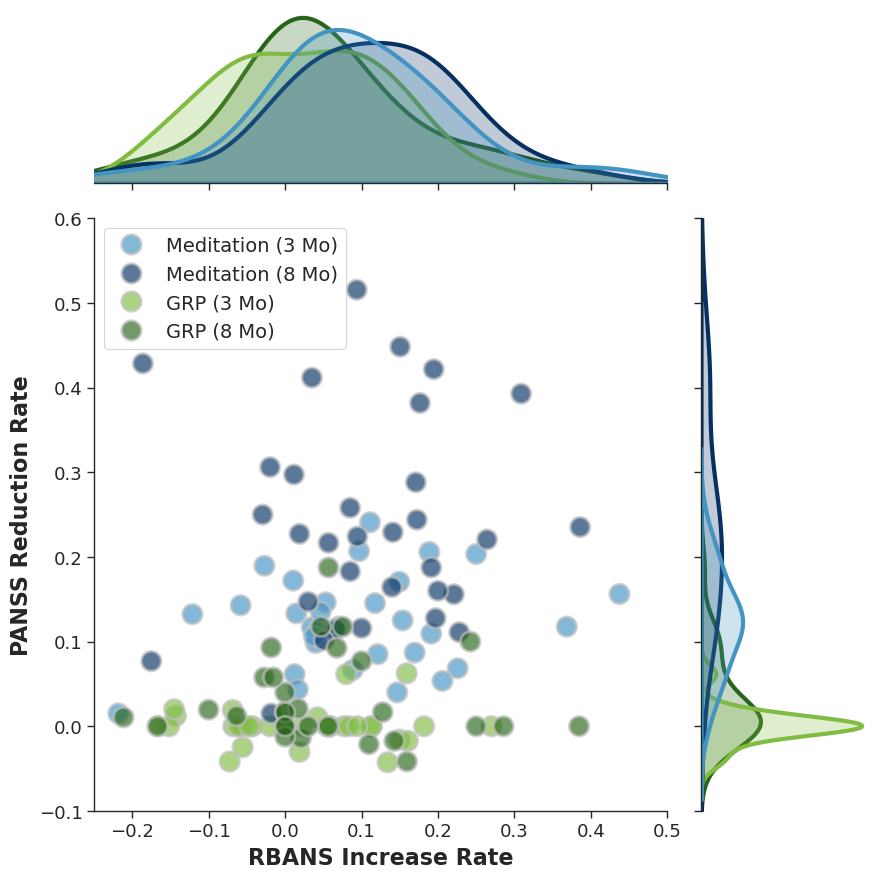

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

save_fig=0

meditation_color = '#4393c3'
meditation_color_l = '#d1e5f0'
meditation_color_d = '#053061' #'#2166ac'

control_color   = '#7fbc41'
control_color_l = '#e6f5d0'
control_color_d = '#276419'

def generate_unified_trajectory_plot(df):
    sns.set_theme(style="ticks", font="sans-serif", context="paper", font_scale=1.2)
    # 1. Create a composite column for the hue mapping
    # This creates labels like 'Control_3', 'Meditation_8', etc.
    plot_df = df.copy()
    plot_df['Group_Time'] = plot_df['group'].astype(str) + '_' + plot_df['session'].astype(str)
    
    # 2. Define the precise 4-color palette
    # Grays for Control, Blues for Meditation (adjust hex codes as needed)
    custom_palette = {
        'control_3': control_color,       # Light Gray
        'control_8': control_color_d,       # Dark Gray
        'meditation_3': meditation_color,    # Light Blue
        'meditation_8': meditation_color_d     # Deep Blue
    }
    legend_order = ['meditation_3', 'meditation_8', 'control_3', 'control_8']
    legend_labels = {
        'control_3': 'GRP (3 Mo)',
        'control_8': 'GRP (8 Mo)',
        'meditation_3': 'Meditation (3 Mo)',
        'meditation_8': 'Meditation (8 Mo)'
    }

    # 3. Generate the Unified JointPlot
    g = sns.jointplot(
        data=plot_df, 
        x='RBANS_inc_rate', 
        y='PANSS_dec_rate', 
        hue='Group_Time',
        palette=custom_palette,
        hue_order=legend_order,
        alpha=0.65,          
        s=200, # Slightly smaller dots to reduce overlap congestion
        edgecolor='silver',   
        linewidth=2,
        height=7.5,
        ratio=3,
        xlim=(-0.25, 0.5), # Tightens the horizontal axis
        ylim=(-0.1, 0.6),  # Tightens the vertical axis
        marginal_kws={'fill': True, 'alpha': 0.25, 'linewidth': 3, 'common_norm': False}
    )
    
    g.set_axis_labels('RBANS Increase Rate', 'PANSS Reduction Rate', weight='bold', fontsize=16)
    g.ax_joint.tick_params(axis='both', which='major', labelsize=13) # Increases the x/y numbers

    g.figure.set_size_inches(9, 9)

    handles, labels = g.ax_joint.get_legend_handles_labels()
    new_labels = [legend_labels[label] for label in labels]
    
    # 4. Clean up the legend
    g.ax_joint.legend(
        handles=handles,
        labels=new_labels,
        fontsize=14,
        frameon=True, 
        loc='upper left'
    )
    
    #g.figure.suptitle('A. Bivariate Trajectories of Clinical and Cognitive Recovery', y=1.03, weight='bold')
    
    return g

joint_plot = generate_unified_trajectory_plot(test_df[test_df['session'].isin([3,8])])
if save_fig==1:
    pdr_rir_file_path = fig_path / "fig2_pdr_rir_scatter.png"
    joint_plot.savefig(pdr_rir_file_path, dpi=330)
plt.show()

## 2. Main clinical and cognition CLPM

In [5]:
## Visualization setup
import os
import time
import matplotlib.pyplot as plt

#time_tag = time.strftime("%Y%m%d")
time_tag = "20260703" 
save_fig = 1

sns.set(style="whitegrid", font_scale=1.2)
# Turn on y-grid, turn off x-grid

meditation_color = '#4393c3'
meditation_color_l = '#d1e5f0'
meditation_color_d = '#2166ac'

control_color   = '#7fbc41'
control_color_l = '#e6f5d0'
control_color_d = '#276419'

LABEL_FONT_SIZE =24
TITLE_FONT_SIZE =24
MARKER_SIZE = 30
DPI_VAL= 330

clpm_file_path  = fig_path / ('clpm_'+time_tag+'.jpg')
mediation_permu_file_path = fig_path / ('mediation_permu_'+time_tag+'.jpg')

clpm_path = data_path / 'clpm'
os.makedirs(clpm_path, exist_ok=True)

In [6]:
import pandas as pd
import semopy
from sklearn.preprocessing import StandardScaler
from IPython.display import display

from utils_.utils_private import report_unified_missingness

# ==========================================
# 1. DATA RESTRUCTURING (WIDE FORMAT)
# ==========================================
basic_vars = ['participant_id', 'group', 'session', 'PANSS_dec_rate', 'RBANS_inc_rate']
covariates = ['RBANS_sum', 'PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose'] 

path_df = test_df[basic_vars + covariates].copy()

# Binarize treatment
path_df['treatment'] = (path_df['group'] == 'meditation').astype(int)

# Pivot longitudinal behavioral variables (3m and 8m rates)
test_df_wide = path_df.pivot(index="participant_id", columns="session", values=["RBANS_inc_rate", "PANSS_dec_rate"])
test_df_wide.columns = [f"{var}_{int(session)}" for var, session in test_df_wide.columns]
test_df_wide.reset_index(inplace=True)

# Extract baseline covariates (Session 0)
baseline_covariates_df = path_df[path_df['session'] == 0][
    ['participant_id', 'treatment', 'CPZ_dose', 'PANSS_SUM_base', 'RBANS_sum_base']
].drop_duplicates()

# Merge into final wide matrix
test_df_wide = test_df_wide.merge(baseline_covariates_df, on='participant_id')

# ==========================================
# 2. STANDARDIZATION (THE CRITICAL ALIGNMENT)
# ==========================================
# Explicitly isolate only the variables used in the SEM to prevent NaNs from unused columns
sem_cols = [
    'RBANS_inc_rate_3', 'PANSS_dec_rate_3', 
    'RBANS_inc_rate_8', 'PANSS_dec_rate_8',
    'treatment', 'PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose'
]

# Guarantee complete cases
report_unified_missingness(test_df_wide, group_col='treatment', session_col='session', show_all=True)    
data_clean = test_df_wide[sem_cols].dropna().copy()
 
# Apply Z-scoring to force all variables (including covariates) onto a mean=0, std=1 scale
scaler = StandardScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data_clean), columns=data_clean.columns)


=== Missing data REPORT (WIDE FORMAT) ===


Enrolled  \
Group      Session                    Variable                           
Control    1. Baseline (0m)           CPZ_dose                      32   
                                      PANSS_SUM_base                32   
                                      RBANS_sum_base                32   
           2. 3-Months                PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
           3. 8-Months                PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
           5. Overall (All Variables) [Complete-Case Cohort]        32   
Meditation 1. Baseline (0m)           CPZ_dose                      32   
                                      PANSS_SUM_base                32   
                                      RBANS_sum_base                32   
           2. 3-Months                PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
           3. 8-Months                PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
           5. Overall (All Variables) [Complete-Case Cohort]        32   

                                                              Preserved  \
Group      Session                    Variable                            
Control    1. Baseline (0m)           CPZ_dose                       32   
                                      PANSS_SUM_base                 32   
                                      RBANS_sum_base                 31   
           2. 3-Months                PANSS_dec_rate                 32   
                                      RBANS_inc_rate                 31   
           3. 8-Months                PANSS_dec_rate                 31   
                                      RBANS_inc_rate                 30   
           5. Overall (All Variables) [Complete-Case Cohort]         30   
Meditation 1. Baseline (0m)           CPZ_dose                       32   
                                      PANSS_SUM_base                 32   
                                      RBANS_sum_base                 32   
           2. 3-Months                PANSS_dec_rate                 32   
                                      RBANS_inc_rate                 32   
           3. 8-Months                PANSS_dec_rate                 32   
                                      RBANS_inc_rate                 32   
           5. Overall (All Variables) [Complete-Case Cohort]         32   

                                                              Dropped  
Group      Session                    Variable                         
Control    1. Baseline (0m)           CPZ_dose                      0  
                                      PANSS_SUM_base                0  
                                      RBANS_sum_base                1  
           2. 3-Months                PANSS_dec_rate                0  
                                      RBANS_inc_rate                1  
           3. 8-Months                PANSS_dec_rate                1  
                                      RBANS_inc_rate                2  
           5. Overall (All Variables) [Complete-Case Cohort]        2  
Meditation 1. Baseline (0m)           CPZ_dose                      0  
                                      PANSS_SUM_base                0  
                                      RBANS_sum_base                0  
           2. 3-Months                PANSS_dec_rate                0  
                                      RBANS_inc_rate                0  
           3. 8-Months                PANSS_dec_rate                0  
                                      RBANS_inc_rate                0  
           5. Overall (All Variables) [Complete-Case Cohort]        0

In [7]:
print(f"=== FINAL SAMPLE SIZE FOR CLINICAL CLPM: N = {len(data_scaled)} ===")

# ==========================================
# 3. SEM MODEL DEFINITION & FITTING
# ==========================================
clpm_model = """
    # 1. Auto-regressive paths (stability over time)
    RBANS_inc_rate_8  ~ RBANS_inc_rate_3
    PANSS_dec_rate_8  ~ PANSS_dec_rate_3

    # 2. Cross-lagged paths (interplay between cognition and symptoms)
    PANSS_dec_rate_8  ~ RBANS_inc_rate_3 
    RBANS_inc_rate_8  ~ PANSS_dec_rate_3

    # 3. Treatment as an exogenous predictor
    RBANS_inc_rate_3  ~ treatment
    RBANS_inc_rate_8  ~ treatment
    PANSS_dec_rate_3  ~ treatment
    PANSS_dec_rate_8  ~ treatment

    # 4. Covariate Controls
    # Adjusting early rates for starting points and medication
    PANSS_dec_rate_3  ~ PANSS_SUM_base + RBANS_sum_base + CPZ_dose
    RBANS_inc_rate_3  ~ PANSS_SUM_base + RBANS_sum_base + CPZ_dose

    # Adjusting late rates to ensure downstream effects are truly independent
    PANSS_dec_rate_8  ~ PANSS_SUM_base + RBANS_sum_base + CPZ_dose
    RBANS_inc_rate_8  ~ PANSS_SUM_base + RBANS_sum_base + CPZ_dose
    
    # Concurrent (Residual) Covariances
    RBANS_inc_rate_3 ~~ PANSS_dec_rate_3
    RBANS_inc_rate_8 ~~ PANSS_dec_rate_8
"""

model = semopy.Model(clpm_model)
model.fit(data_scaled)

print("\n=== PURE CLINICAL MODEL PARAMETERS (STANDARDIZED) ===")
# Generate standard estimates
results = model.inspect(std_est=True)
display(results)

print("\n=== GLOBAL FIT STATISTICS ===")
model_stats= semopy.calc_stats(model)
display(model_stats)

results.to_csv(clpm_path / 'Supplementary_Table_CLPM_main.csv', index=False)
model_stats.to_csv(clpm_path / 'Supplementary_Table_FitStats_main.csv', index=False)

=== FINAL SAMPLE SIZE FOR CLINICAL CLPM: N = 62 ===

=== PURE CLINICAL MODEL PARAMETERS (STANDARDIZED) ===


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,RBANS_inc_rate_3,~,treatment,0.330636,0.330648,0.131400,2.516247,1.186122e-02
1,RBANS_inc_rate_3,~,PANSS_SUM_base,-0.002082,-0.002082,0.122223,-0.017032,9.864108e-01
2,RBANS_inc_rate_3,~,RBANS_sum_base,-0.087752,-0.087756,0.135092,-0.649576,5.159663e-01
3,RBANS_inc_rate_3,~,CPZ_dose,-0.206864,-0.206872,0.122726,-1.685584,9.187595e-02
4,PANSS_dec_rate_3,~,treatment,0.725144,0.725108,0.080262,9.034759,0.000000e+00
5,PANSS_dec_rate_3,~,PANSS_SUM_base,0.064590,0.064586,0.074656,0.865165,3.869483e-01
6,PANSS_dec_rate_3,~,RBANS_sum_base,0.163986,0.163978,0.082516,1.987319,4.688708e-02
7,PANSS_dec_rate_3,~,CPZ_dose,-0.087170,-0.087165,0.074963,-1.162839,2.448948e-01
8,RBANS_inc_rate_8,~,RBANS_inc_rate_3,0.563168,0.563129,0.110399,5.101210,3.374892e-07
9,RBANS_inc_rate_8,~,PANSS_dec_rate_3,0.038959,0.038960,0.180740,0.215552,8.293369e-01



=== GLOBAL FIT STATISTICS ===


,DoF,DoF Baseline,chi2,chi2 p-value,chi2 Baseline,CFI,GFI,AGFI,NFI,TLI,RMSEA,AIC,BIC,LogLik
Value,10,32,0.000011,1.0,221.571612,1.05275,1.0,1.0,1.0,1.168801,0,52.0,107.305494,1.786682e-07


### Simple visualization

,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,RBANS_inc_rate_3,~,treatment,0.330636,0.330648,0.131400,2.516247,1.186122e-02
4,PANSS_dec_rate_3,~,treatment,0.725144,0.725108,0.080262,9.034759,0.000000e+00
8,RBANS_inc_rate_8,~,RBANS_inc_rate_3,0.563168,0.563129,0.110399,5.101210,3.374892e-07
9,RBANS_inc_rate_8,~,PANSS_dec_rate_3,0.038959,0.038960,0.180740,0.215552,8.293369e-01
10,RBANS_inc_rate_8,~,treatment,0.054155,0.054153,0.172813,0.313375,7.539959e-01
14,PANSS_dec_rate_8,~,PANSS_dec_rate_3,0.546224,0.546201,0.110577,4.939760,7.821897e-07
15,PANSS_dec_rate_8,~,RBANS_inc_rate_3,0.135963,0.135945,0.067542,2.013003,4.411436e-02
16,PANSS_dec_rate_8,~,treatment,0.278218,0.278192,0.105727,2.631464,8.501776e-03


CLPM Diagram saved as /scratch/repo_sz_meditation/fig/clpm_20260703.jpg.pdf


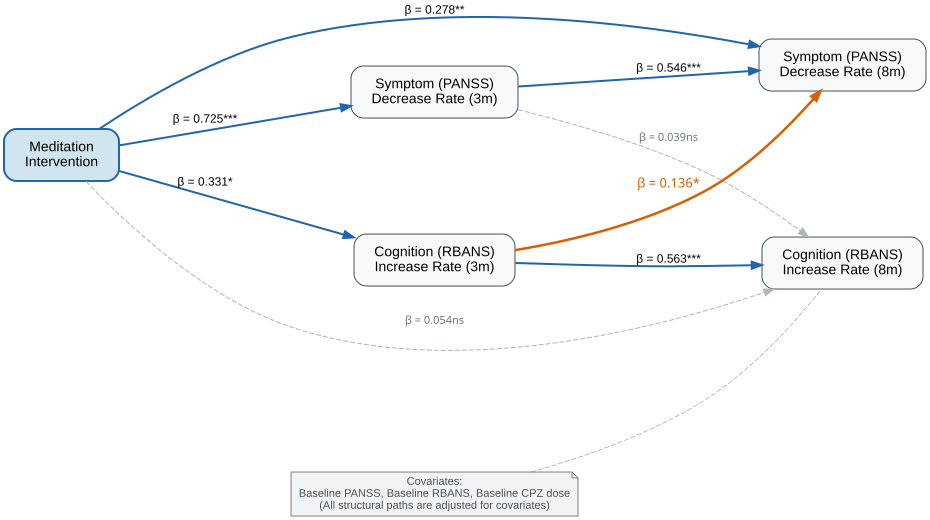

In [8]:
import pandas as pd
import graphviz

def get_asterisks(p):
    """Converts p-value to standard significance asterisks."""
    if p < 0.001: return '***'
    if p < 0.01: return '**'
    if p < 0.05: return '*'
    return 'ns'

def generate_dynamic_clpm(results_df, save_path=None):
    """
    Generates a publication-ready CLPM directly from the semopy results dataframe.
    """
    
    # 1. Dynamically Filter the Data
    covariates = ['PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose']
    
    plot_df = results_df[
        (results_df['op'] == '~') & 
        (~results_df['rval'].isin(covariates))
    ].copy()

    # 2. Initialize Graphviz
    dot = graphviz.Digraph(comment='Cross-Lagged Panel Model', format='pdf')
    dot.attr(rankdir='LR', splines='spline', nodesep='0.8', ranksep='1.5', fontname='Arial')

    node_attr = {
        'shape': 'box', 'style': 'rounded,filled', 
        'fillcolor': '#f8f9fa', 'color': '#495057', 
        'fontname': 'Arial', 'fontsize': '14', 'margin': '0.3,0.15'
    }

    # 3. Create Nodes (Columns)
    tx_attr = node_attr.copy()
    tx_attr.update({'fillcolor': '#d1e5f0', 'color': '#2166ac', 'penwidth': '2'})
    dot.node('Tx', 'Meditation\nIntervention', **tx_attr)

    # Force vertical ordering using invisible edges
    with dot.subgraph() as s3:
        s3.attr(rank='same') 
        s3.node('P3', 'Symptom (PANSS)\nDecrease Rate (3m)', **node_attr)
        s3.node('R3', 'Cognition (RBANS)\nIncrease Rate (3m)', **node_attr)
        s3.edge('P3', 'R3', style='invis') # Forces PANSS strictly above RBANS

    with dot.subgraph() as s8:
        s8.attr(rank='same')
        s8.node('P8', 'Symptom (PANSS)\nDecrease Rate (8m)', **node_attr)
        s8.node('R8', 'Cognition (RBANS)\nIncrease Rate (8m)', **node_attr)
        s8.edge('P8', 'R8', style='invis') # Forces PANSS strictly above RBANS

    dot.node('Cov', 'Covariates:\nBaseline PANSS, Baseline RBANS, Baseline CPZ dose\n(All structural paths are adjusted for covariates)', 
             shape='note', style='filled', fillcolor='#f1f3f5', color='grey', 
             fontname='Arial', fontsize='11', fontcolor='#495057')

    # Mapping raw semopy variable names to Graphviz IDs
    node_map = {
        'treatment': 'Tx',
        'RBANS_inc_rate_3': 'R3',
        'PANSS_dec_rate_3': 'P3',
        'RBANS_inc_rate_8': 'R8',
        'PANSS_dec_rate_8': 'P8'
    }
    display(plot_df)
    # 4. Dynamically Draw Edges from the DataFrame
    for _, row in plot_df.iterrows():
        source = node_map.get(row['rval'])
        target = node_map.get(row['lval'])
        
        if not source or not target:
            continue
            
        # FIX 1: Explicitly pull the standardized estimate
        est = row['Est. Std']  
        p_val = row['p-value']
        sig_str = get_asterisks(p_val)
        
        # FIX 2: Use the standard β symbol instead of b
        edge_label = f'β = {est:.3f}{sig_str}'
        
        # Style Logic
        if p_val < 0.05:
            # Highlight the cross-lagged discovery path
            if source == 'R3' and target == 'P8':
                edge_style = {'style': 'solid', 'color': '#d95f02', 'penwidth': '2.5', 'fontcolor': '#d95f02', 'fontsize': '13', 'fontname': 'Arial-Bold'}
            else:
                edge_style = {'style': 'solid', 'color': '#2166ac', 'penwidth': '2.0', 'fontcolor': 'black', 'fontsize': '12', 'fontname': 'Arial'}
        else:
            edge_style = {'style': 'dashed', 'color': '#adb5bd', 'penwidth': '1.0', 'fontcolor': '#6c757d', 'fontsize': '11', 'fontname': 'Arial-Italic'}

        dot.edge(source, target, label=edge_label, **edge_style)

    # Position the covariate box below the graph visually
    dot.edge('Cov', 'R8', style='dashed', color='grey', penwidth='0.5', arrowhead='none')

    # 5. Render
    if save_path:
        dot.render(save_path, view=False, cleanup=True)
        print(f"CLPM Diagram saved as {save_path}.pdf")
    
    display(dot)
    
# Ensure you pass the RAW results dataframe from semopy 
# before any string-mapping operations are applied to it:
# results = model.inspect(std_est=True)
generate_dynamic_clpm(results, save_path=clpm_file_path)

## 2.1 Sensitivity analysis for model with duration

Because duration is non-significant across all four of its paths in the SEM, it is acting as "dead weight." This is mathematically proven by the Information Criteria:

Model Without Duration: AIC = 52.0, BIC = 107.7

Model With Duration: AIC = 60.0, BIC = 121.8

The model without duration is substantially superior. By adding duration, you burned 4 degrees of freedom and penalized your model fit without explaining any new variance.

To ensure the observed longitudinal trajectories were not artifacts of illness chronicity, we conducted a sensitivity CLPM explicitly controlling for illness duration. The behavioral cross-lagged effect (early cognitive gains predicting late symptom reduction) remained highly significant ($\beta = 0.155, p = 0.027$), confirming that this behavioral relationship is robust to disease stage. Furthermore, illness duration did not significantly predict any acute or chronic rates of clinical change (all $p > 0.26$). This indicates that the intervention's efficacy is preserved across varying levels of chronicity, and confirms that the subsequent attenuation of the behavioral cross-lagged effect in the neuro-clinical model was strictly driven by the introduction of network effective connectivity, rather than demographic confounders.


In [9]:
import pandas as pd
import semopy
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# 1. Isolate Data and Drop NaNs
cols_to_keep = [
    'RBANS_inc_rate_3', 'PANSS_dec_rate_3', 'RBANS_inc_rate_8', 'PANSS_dec_rate_8', 
    'treatment', 'PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose', 'duration'
]

# ==========================================
# 1. DATA RESTRUCTURING (WIDE FORMAT)
# ==========================================
basic_vars = ['participant_id', 'group', 'session', 'PANSS_dec_rate', 'RBANS_inc_rate']
covariates = ['RBANS_sum', 'PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose', 'duration'] 

path_df = test_df[basic_vars + covariates].copy()

# Binarize treatment
path_df['treatment'] = (path_df['group'] == 'meditation').astype(int)

# Pivot longitudinal behavioral variables (3m and 8m rates)
test_df_wide = path_df.pivot(index="participant_id", columns="session", values=["RBANS_inc_rate", "PANSS_dec_rate"])
test_df_wide.columns = [f"{var}_{int(session)}" for var, session in test_df_wide.columns]
test_df_wide.reset_index(inplace=True)

# Extract baseline covariates (Session 0)
baseline_covariates_df = path_df[path_df['session'] == 0][
    ['participant_id', 'treatment', 'CPZ_dose', 'PANSS_SUM_base', 'RBANS_sum_base', 'duration']
].drop_duplicates()

# Merge into final wide matrix
test_df_wide = test_df_wide.merge(baseline_covariates_df, on='participant_id')


data = test_df_wide[cols_to_keep].copy()
report_unified_missingness(data, group_col='treatment', session_col='session', show_all=True)    
data = data.apply(pd.to_numeric, errors='coerce').dropna()

# 2. Standardize Data (Z-Score)
scaler = StandardScaler()
data_scaled = pd.DataFrame(scaler.fit_transform(data), columns=cols_to_keep)

# 3. Define the Updated Clinical CLPM Model (Controlling for Chronicity)
clpm_model_duration = """
    # 1. Auto-regressive paths
    RBANS_inc_rate_8  ~ RBANS_inc_rate_3
    PANSS_dec_rate_8  ~ PANSS_dec_rate_3

    # 2. Cross-lagged paths
    PANSS_dec_rate_8  ~ RBANS_inc_rate_3 
    RBANS_inc_rate_8  ~ PANSS_dec_rate_3

    # 3. Treatment
    RBANS_inc_rate_3  ~ treatment
    RBANS_inc_rate_8  ~ treatment
    PANSS_dec_rate_3  ~ treatment
    PANSS_dec_rate_8  ~ treatment

    # 4. Covariates (Base + Meds + Duration)
    PANSS_dec_rate_3  ~ PANSS_SUM_base + RBANS_sum_base + CPZ_dose + duration
    RBANS_inc_rate_3  ~ PANSS_SUM_base + RBANS_sum_base + CPZ_dose + duration
    PANSS_dec_rate_8  ~ PANSS_SUM_base + RBANS_sum_base + CPZ_dose + duration
    RBANS_inc_rate_8  ~ PANSS_SUM_base + RBANS_sum_base + CPZ_dose + duration
    
    # 5. Residual Covariances
    RBANS_inc_rate_3 ~~ PANSS_dec_rate_3
    RBANS_inc_rate_8 ~~ PANSS_dec_rate_8
"""

# 4. Fit Model
model_sens = semopy.Model(clpm_model_duration)
model_sens.fit(data_scaled)

# 5. Inspect Results (Forcing Standardized Estimates)
results_sens = model_sens.inspect(std_est=True)

print("=== SENSITIVITY CLINICAL CLPM (Controlling for Duration) ===")
display(results_sens)

print("\n=== GLOBAL FIT STATISTICS ===")
stats_sens = semopy.calc_stats(model_sens)
display(stats_sens)

# ==========================================
# 6. EXPORT ALL MODELS TO SUPPLEMENTARY CSVS
# ==========================================
# Export the Sensitivity Model
results_sens.to_csv(clpm_path / 'Supplementary_Table_CLPM_Sensitivity_Duration.csv', index=False)
stats_sens.to_csv(clpm_path / 'Supplementary_Table_FitStats_Sensitivity.csv', index=False)


=== Missing data REPORT (WIDE FORMAT) ===


Enrolled  \
Group      Session                    Variable                           
Control    1. Baseline (0m)           CPZ_dose                      32   
                                      PANSS_SUM_base                32   
                                      RBANS_sum_base                32   
                                      duration                      32   
           2. 3-Months                PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
           3. 8-Months                PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
           5. Overall (All Variables) [Complete-Case Cohort]        32   
Meditation 1. Baseline (0m)           CPZ_dose                      32   
                                      PANSS_SUM_base                32   
                                      RBANS_sum_base                32   
                                      duration                      32   
           2. 3-Months                PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
           3. 8-Months                PANSS_dec_rate                32   
                                      RBANS_inc_rate                32   
           5. Overall (All Variables) [Complete-Case Cohort]        32   

                                                              Preserved  \
Group      Session                    Variable                            
Control    1. Baseline (0m)           CPZ_dose                       32   
                                      PANSS_SUM_base                 32   
                                      RBANS_sum_base                 31   
                                      duration                       30   
           2. 3-Months                PANSS_dec_rate                 32   
                                      RBANS_inc_rate                 31   
           3. 8-Months                PANSS_dec_rate                 31   
                                      RBANS_inc_rate                 30   
           5. Overall (All Variables) [Complete-Case Cohort]         28   
Meditation 1. Baseline (0m)           CPZ_dose                       32   
                                      PANSS_SUM_base                 32   
                                      RBANS_sum_base                 32   
                                      duration                       30   
           2. 3-Months                PANSS_dec_rate                 32   
                                      RBANS_inc_rate                 32   
           3. 8-Months                PANSS_dec_rate                 32   
                                      RBANS_inc_rate                 32   
           5. Overall (All Variables) [Complete-Case Cohort]         30   

                                                              Dropped  
Group      Session                    Variable                         
Control    1. Baseline (0m)           CPZ_dose                      0  
                                      PANSS_SUM_base                0  
                                      RBANS_sum_base                1  
                                      duration                      2  
           2. 3-Months                PANSS_dec_rate                0  
                                      RBANS_inc_rate                1  
           3. 8-Months                PANSS_dec_rate                1  
                                      RBANS_inc_rate                2  
           5. Overall (All Variables) [Complete-Case Cohort]        4  
Meditation 1. Baseline (0m)           CPZ_dose                      0  
                                      PANSS_SUM_base                0  
                                      RBANS_sum_base                0  
                                      duration                      2  


=== SENSITIVITY CLINICAL CLPM (Controlling for Duration) ===


,lval,op,rval,Estimate,Est. Std,Std. Err,z-value,p-value
0,RBANS_inc_rate_3,~,treatment,0.332961,0.332961,0.139206,2.391860,1.676324e-02
1,RBANS_inc_rate_3,~,PANSS_SUM_base,-0.014375,-0.014375,0.126358,-0.113766,9.094234e-01
2,RBANS_inc_rate_3,~,RBANS_sum_base,-0.103243,-0.103243,0.141394,-0.730179,4.652808e-01
3,RBANS_inc_rate_3,~,CPZ_dose,-0.197978,-0.197978,0.128003,-1.546670,1.219428e-01
4,RBANS_inc_rate_3,~,duration,0.023055,0.023055,0.125353,0.183920,8.540763e-01
5,PANSS_dec_rate_3,~,treatment,0.692540,0.692516,0.086075,8.045751,8.881784e-16
6,PANSS_dec_rate_3,~,PANSS_SUM_base,0.068991,0.068988,0.078131,0.883016,3.772276e-01
7,PANSS_dec_rate_3,~,RBANS_sum_base,0.169257,0.169251,0.087428,1.935959,5.287276e-02
8,PANSS_dec_rate_3,~,CPZ_dose,-0.105046,-0.105042,0.079148,-1.327206,1.844404e-01
9,PANSS_dec_rate_3,~,duration,-0.078866,-0.078863,0.077509,-1.017501,3.089154e-01



=== GLOBAL FIT STATISTICS ===


,DoF,DoF Baseline,chi2,chi2 p-value,chi2 Baseline,CFI,GFI,AGFI,NFI,TLI,RMSEA,AIC,BIC,LogLik
Value,15,41,0.000014,1.0,209.48746,1.089027,1.0,1.0,1.0,1.243341,0,60.0,121.81329,2.444183e-07


## 3. Permutation test for RIR3->PDR8 mediation effect
model_1_str = "RBANS_inc_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose"

model_2_str = "PANSS_dec_rate_8 ~ RBANS_inc_rate_3 + PANSS_dec_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose"

model_direct_str = "PANSS_dec_rate_8 ~ treatment + PANSS_dec_rate_3 + PANSS_SUM_base + RBANS_sum_base + CPZ_dose"

In [10]:
import pandas as pd
import numpy as np
import statsmodels.formula.api as smf
from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler
from joblib import Parallel, delayed

n_boot = 10000

# 1. Standardize the data to extract Standardized Beta (β) weights
# We use the 'treatment' integer column (0/1) instead of the categorical 'group'
vars_to_scale = [
    'treatment', 'RBANS_inc_rate_3', 'PANSS_dec_rate_8', 'PANSS_dec_rate_3', 
    'PANSS_SUM_base', 'RBANS_sum_base', 'CPZ_dose'
]

scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(test_df_wide[vars_to_scale]), columns=vars_to_scale)

# 2. Architect the equations to perfectly mirror the CLPM
# Model A: Treatment -> Early Cognition
model_a_str = "RBANS_inc_rate_3 ~ treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose"

# Model B: Early Cognition -> Late Symptoms (CRITICAL: Must include PANSS_dec_rate_3 autoregression)
model_b_str = "PANSS_dec_rate_8 ~ RBANS_inc_rate_3 + PANSS_dec_rate_3 + treatment + PANSS_SUM_base + RBANS_sum_base + CPZ_dose"

# Total Effect Model
model_direct_str = "PANSS_dec_rate_8 ~ treatment + PANSS_dec_rate_3 + PANSS_SUM_base + RBANS_sum_base + CPZ_dose"

# 3. Point Estimates on original scaled data
model_a = smf.ols(model_a_str, data=df_scaled).fit()
model_b = smf.ols(model_b_str, data=df_scaled).fit()
total_effect_model = smf.ols(model_direct_str, data=df_scaled).fit()

a_path = model_a.params["treatment"]
b_path = model_b.params["RBANS_inc_rate_3"]
indirect_effect = a_path * b_path
direct_effect = model_b.params["treatment"]
total_effect_val = total_effect_model.params["treatment"]

# 4. Define the Bootstrap Function
def bootstrap_mediation(df, seed=None):
    sample = resample(df, replace=True, n_samples=len(df), random_state=seed)
    try:
        m_a = smf.ols(model_a_str, data=sample).fit()
        m_b = smf.ols(model_b_str, data=sample).fit()
        a_b = m_a.params["treatment"] * m_b.params["RBANS_inc_rate_3"]
    except Exception:
        a_b = np.nan
    return a_b

# 5. Run Parallel Bootstrapping (Using all available cores)
print(f"Running {n_boot} bootstraps across multiple cores...")
boot_ests = Parallel(n_jobs=-1)(delayed(bootstrap_mediation)(df_scaled, seed) for seed in range(n_boot))
boot_ests = np.array([x for x in boot_ests if not np.isnan(x)])

# 6. Calculate 95% Confidence Interval and Empirical P-value
ci_lower, ci_upper = np.percentile(boot_ests, [2.5, 97.5])

# Two-tailed empirical p-value calculation
p_value = np.mean((boot_ests > 0) == (indirect_effect < 0)) * 2

Running 10000 bootstraps across multiple cores...


/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/opt/conda/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"
/opt

In [11]:
print("\n=== STANDARDIZED MEDIATION EFFECTS (CLPM) ===")
print(f"Total effect (β):    {total_effect_val:.3f}")
print(f"Direct effect (β):   {direct_effect:.3f}")
print(f"Indirect effect (β): {indirect_effect:.3f}")
print(f"10,000 Boot 95% CI:  [{ci_lower:.3f}, {ci_upper:.3f}]")
print(f"Empirical P-value:   {p_value:.3f}")


=== STANDARDIZED MEDIATION EFFECTS (CLPM) ===
Total effect (β):    0.301
Direct effect (β):   0.279
Indirect effect (β): 0.043
10,000 Boot 95% CI:  [-0.015, 0.150]
Empirical P-value:   0.182


=== STANDARDIZED MEDIATION RESULTS ===
Total effect (β):    0.301
Direct effect (β):   0.279
Indirect effect (β): 0.043 (95% CI: [-0.015, 0.150])
Bootstrap p-value:    0.182
Figure saved at: /scratch/repo_sz_meditation/fig/mediation_permu_20260703.jpg


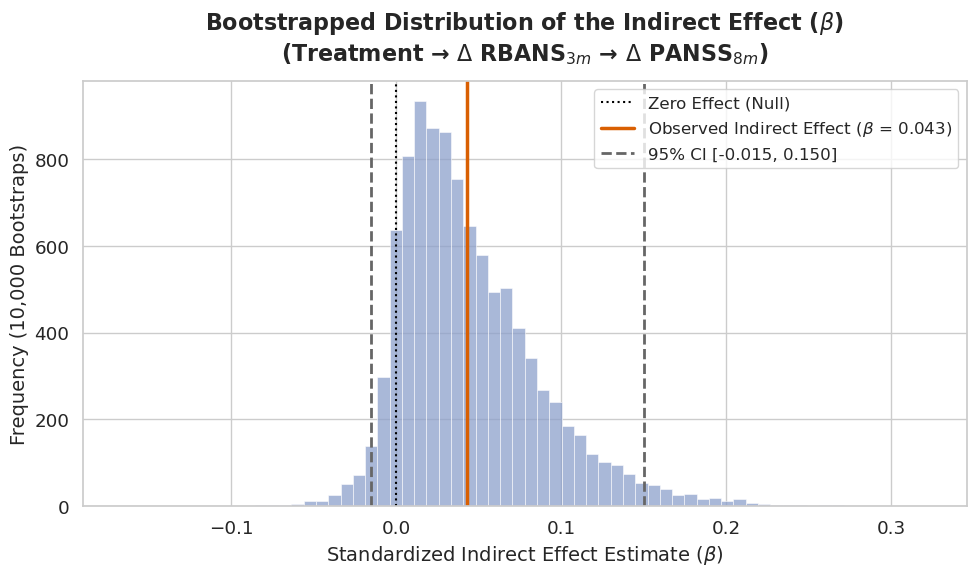

In [12]:
import matplotlib.pyplot as plt

save_fig = 1
TITLE_FONT_SIZE = 16
LABEL_FONT_SIZE = 14

fig, ax = plt.subplots(figsize=(10, 6))

# 1. Plot the distribution of bootstrapped estimates (10,000 resamples)
ax.hist(boot_ests, bins=60, alpha=0.75, color='#8da0cb', edgecolor='white', linewidth=0.5)

# 2. Add structural reference lines
# The Zero Line (The Null Hypothesis)
ax.axvline(0, color='black', lw=1.5, linestyle=':', label='Zero Effect (Null)')

# The Observed Effect
ax.axvline(indirect_effect, color='#d95f02', lw=2.5, linestyle='-', 
           label=f'Observed Indirect Effect ($\\beta$ = {indirect_effect:.3f})')

# The 95% Confidence Interval
ax.axvline(ci_lower, color='#666666', lw=2, linestyle='--', 
           label=f'95% CI [{ci_lower:.3f}, {ci_upper:.3f}]')
ax.axvline(ci_upper, color='#666666', lw=2, linestyle='--')

# 3. Dynamic styling and labels
ax.set_title("Bootstrapped Distribution of the Indirect Effect ($\\beta$)\n(Treatment → $\Delta$ RBANS$_{3m}$ → $\Delta$ PANSS$_{8m}$)", 
             fontsize=TITLE_FONT_SIZE, fontweight='bold', pad=15)
ax.set_xlabel('Standardized Indirect Effect Estimate ($\\beta$)', fontsize=LABEL_FONT_SIZE)
ax.set_ylabel('Frequency (10,000 Bootstraps)', fontsize=LABEL_FONT_SIZE)

# Dynamically scale the X-axis so it never cuts off the tails
x_margin = (boot_ests.max() - boot_ests.min()) * 0.1
ax.set_xlim(boot_ests.min() - x_margin, boot_ests.max() + x_margin)

# Clean up chart junk for a modern, rigorous aesthetic
#ax.spines['top'].set_visible(False)
#ax.spines['right'].set_visible(False)
ax.legend(fontsize=LABEL_FONT_SIZE-2, loc='upper right', frameon=True)

plt.tight_layout()

# 4. Print formatted console output
print('=== STANDARDIZED MEDIATION RESULTS ===')
print(f'Total effect (\u03B2):    {total_effect_val:.3f}')
print(f'Direct effect (\u03B2):   {direct_effect:.3f}')
print(f'Indirect effect (\u03B2): {indirect_effect:.3f} (95% CI: [{ci_lower:.3f}, {ci_upper:.3f}])')
print(f'Bootstrap p-value:    {p_value:.3f}')

if save_fig:
    # Ensure DPI_VAL and mediation_permu_file_path are defined earlier in your notebook
    print(f'Figure saved at: {mediation_permu_file_path}')
    plt.savefig(mediation_permu_file_path, dpi=300, bbox_inches='tight')
else:
    plt.show()